# Etapa 2 · Modelos, métricas y resultados

Este cuaderno **no entrena nada**: lee lo que deja `scripts/run_experiments.py` en `results/` y lo presenta en tablas y gráficos. Así cualquiera puede revisar los resultados sin esperar los 10-20 minutos de entrenamiento.

**Cómo regenerar los resultados desde cero** (desde la raíz del repo):

```bash
python src/build_dataset.py --version v1
python scripts/run_experiments.py --data data/processed/dataset_v1.parquet --stage dev
# opcional, para la comparación sin historial:
python src/build_dataset.py --version v0
python scripts/run_experiments.py --data data/processed/dataset_v0.parquet --stage dev --out results_v0
```

Todo lo que aparece aquí es **validación (2004)**. El test (2005) se evalúa una sola vez al final con `--stage final`; si ya se corrió, la última sección lo muestra.

In [1]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

warnings.filterwarnings("ignore", message="IProgress not found")
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

# Raíz del repo: la carpeta que contiene results/ (sirve si el cuaderno se abre desde notebooks/ o desde la raíz)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "results").is_dir())
RES = ROOT / "results"
RES_V0 = ROOT / "results_v0"          # opcional
CFG = json.loads((ROOT / "configs" / "experiment.json").read_text())

val = pd.read_csv(RES / "val_metrics.csv").set_index("model")
info = json.loads((RES / "run_info.json").read_text())
feats = json.loads((RES / "features.json").read_text())
print(f"Corrida: {info['when']} · Python {info['python']} · semilla {info['seed']} · {info['n_rows']:,} filas")
print(f"{len(feats)} features: {feats}")

Corrida: 2026-11-06T20:33:16 · Python 3.14.3 · semilla 42 · 79,447 filas
22 features: ['horse_age', 'horse_country', 'horse_type', 'horse_rating', 'declared_weight', 'actual_weight', 'draw', 'venue', 'config', 'surface', 'distance', 'going', 'horse_ratings', 'prize', 'race_class', 'field_size', 'horse_win_rate', 'jockey_win_rate', 'trainer_win_rate', 'horse_days_since_last', 'horse_no_history', 'gear_any']


## 1. Escalera de modelos en validación (2004)

Cada escalón agrega una sola idea respecto al anterior (Sección IV-E del paper):

| Escalón | Qué agrega |
|---|---|
| `random` | Piso: elige al azar dentro del campo |
| `market` | Referencia externa: el favorito de las cuotas finales (no es feature) |
| `logreg` | Baseline simple: gana / no gana, caballo por caballo |
| `gbm_binary` | Lo mismo, con no linealidad (gradient boosting) |
| `clogit` | Normaliza dentro de la carrera: las probabilidades suman 1 |
| `lambdamart` | Aprende del orden completo de llegada (modelo propuesto) |

Todas las métricas se promedian **por carrera**, no por fila. Los intervalos son IC 95 % por *bootstrap* remuestreando carreras. `Δ vs mercado` es la diferencia **pareada** de top-1 contra el favorito, en las mismas carreras: si su IC incluye 0, no se puede afirmar que el modelo es distinto del mercado.

In [2]:
orden = ["random", "market", "logreg", "gbm_binary", "clogit", "lambdamart"]
v = val.reindex([m for m in orden if m in val.index])
pct = lambda x: f"{100*x:.1f}"
tabla = pd.DataFrame({
    "top-1 % [IC 95 %]": [f"{pct(r.top1)} [{pct(r.top1_lo)}–{pct(r.top1_hi)}]" for r in v.itertuples()],
    "Δ vs mercado (pp) [IC]": [
        "—" if pd.isna(r.top1_diff_vs_ref) else
        f"{100*r.top1_diff_vs_ref:+.1f} [{100*r.top1_diff_lo:+.1f}, {100*r.top1_diff_hi:+.1f}]"
        for r in v.itertuples()],
    "MRR": v["mrr"], "NDCG@3": v["ndcg@3"], "AUC intra": v["auc_race"],
    "log loss": v["log_loss"], "Brier": v["brier_race"], "ECE": v["ece"],
}, index=v.index)
tabla

,top-1 % [IC 95 %],Δ vs mercado (pp) [IC],MRR,NDCG@3,AUC intra,log loss,Brier,ECE
model,,,,,,,,
random,8.1 [8.0–8.2],"-25.0 [-28.2, -21.8]",0.2477,0.2599,0.4871,2.5228,0.9184,0.0001
market,33.1 [29.9–36.4],—,0.5235,0.5689,0.7859,1.9968,0.8117,0.0048
logreg,23.4 [20.5–26.6],"-9.6 [-13.1, -6.1]",0.4196,0.4614,0.6805,2.3310,0.8814,0.0073
gbm_binary,19.8 [17.0–22.7],"-13.3 [-16.9, -9.8]",0.4104,0.4567,0.6962,2.3121,0.8813,0.0055
clogit,22.8 [19.9–26.0],"-10.3 [-13.8, -6.7]",0.4144,0.4535,0.6744,2.3421,0.8838,0.0063
lambdamart,20.5 [17.9–23.4],"-12.5 [-16.2, -9.1]",0.4083,0.4558,0.6898,2.2986,0.8783,0.0061


**Referencias de literatura** (no son directamente comparables; ver la nota de cada una). Chavan et al. reportan *accuracy por fila* con partición aleatoria: un modelo que nunca predice ganador ya saca ~92 %, por eso no se compara contra nuestro top-1.

In [3]:
pd.DataFrame(CFG["literature"])

,source,metric,value,note
0,"Silverman (2012), Hong Kong, 2,973 carreras",top1,0.2160,"Predice el caballo mÃ¡s rÃ¡pido estimado, no e..."
1,"Chavan et al. (2024), mismo dataset de Kaggle",accuracy por fila,0.9200,Split aleatorio 80/20; el Dummy Classifier tam...


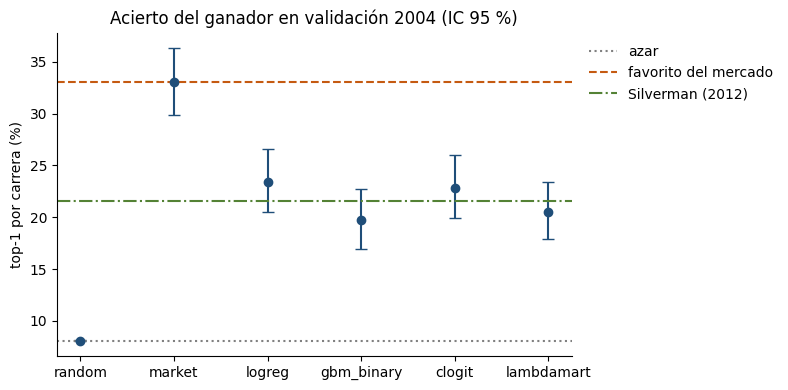

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
x = range(len(v))
ax.errorbar(x, 100 * v["top1"], yerr=[100 * (v["top1"] - v["top1_lo"]), 100 * (v["top1_hi"] - v["top1"])],
            fmt="o", capsize=4, color="#1f4e79")
ax.axhline(100 * v.loc["random", "top1"], ls=":", color="grey", label="azar")
ax.axhline(100 * v.loc["market", "top1"], ls="--", color="#c55a11", label="favorito del mercado")
silv = next((l["value"] for l in CFG["literature"] if l["source"].startswith("Silverman")), None)
if silv:
    ax.axhline(100 * silv, ls="-.", color="#548235", label="Silverman (2012)")
ax.set_xticks(list(x), v.index)
ax.set_ylabel("top-1 por carrera (%)")
ax.set_title("Acierto del ganador en validación 2004 (IC 95 %)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

In [5]:
modelos = v.drop(index=["random", "market"])
mejor = modelos["mrr"].idxmax()
print(f"Mejor modelo por MRR en validación: {mejor} (MRR {modelos.loc[mejor,'mrr']:.3f}, "
      f"top-1 {100*modelos.loc[mejor,'top1']:.1f} %)")
for m, r in modelos.iterrows():
    sig = "SÍ" if (r.top1_diff_hi < 0 or r.top1_diff_lo > 0) else "no"
    print(f"  {m:11s}: ¿distinto del mercado con IC 95 %? {sig}  (Δ {100*r.top1_diff_vs_ref:+.1f} pp)")

Mejor modelo por MRR en validación: logreg (MRR 0.420, top-1 23.4 %)
  logreg     : ¿distinto del mercado con IC 95 %? SÍ  (Δ -9.6 pp)
  gbm_binary : ¿distinto del mercado con IC 95 %? SÍ  (Δ -13.3 pp)
  clogit     : ¿distinto del mercado con IC 95 %? SÍ  (Δ -10.3 pp)
  lambdamart : ¿distinto del mercado con IC 95 %? SÍ  (Δ -12.5 pp)


## 2. Búsqueda de hiperparámetros

Protocolo (detalle y justificación en `docs/busqueda_hiperparametros.md`):

- **Optuna (TPE)** con semilla fija; todos los modelos con hiperparámetros se tunean con el mismo protocolo, no solo el propuesto.
- **Validación cruzada *forward chaining*** dentro de train: entrena ≤ 2000 / valida 2001, ≤ 2001 / 2002, ≤ 2002 / 2003. Nunca se baraja, y ni 2004 ni 2005 participan.
- **Objetivo:** MRR medio en los 3 folds (se reporta media ± desviación estándar).
- En los modelos de árboles el número de árboles sale de *early stopping* en los folds; el modelo final se reentrena con ese número fijo.

In [6]:
rows = []
for f in sorted((RES / "tuning").glob("*_best.json")):
    b = json.loads(f.read_text())
    rows.append({"modelo": b["model"], "pruebas": b["n_trials"], "folds": b["n_folds"],
                 "CV MRR": f"{b['best_cv_mrr']:.4f} ± {b['best_cv_mrr_std']:.4f}",
                 "CV top-1": f"{100*b['best_cv_top1']:.1f} ± {100*b['best_cv_top1_std']:.1f} %",
                 "segundos": b["seconds"], "s / prueba": b["seconds_per_trial"],
                 "mejores hiperparámetros": {k: (round(x, 4) if isinstance(x, float) else x)
                                             for k, x in b["best_params"].items()}})
tun = pd.DataFrame(rows).set_index("modelo")
print(f"Costo total de la búsqueda: {tun['segundos'].sum()/60:.1f} min")
tun

Costo total de la búsqueda: 3.7 min


,pruebas,folds,CV MRR,CV top-1,segundos,s / prueba,mejores hiperparámetros
modelo,,,,,,,
clogit,15,3,0.3858 ± 0.0197,19.2 ± 2.3 %,44.1000,2.9400,{'alpha': 0.0039}
gbm_binary,40,3,0.4005 ± 0.0128,21.0 ± 1.4 %,60.9000,1.5200,"{'learning_rate': 0.1476, 'num_leaves': 10, 'm..."
lambdamart,40,3,0.4062 ± 0.0137,21.5 ± 1.4 %,87.0000,2.1700,"{'learning_rate': 0.0551, 'num_leaves': 13, 'm..."
logreg,15,3,0.3859 ± 0.0185,18.9 ± 2.0 %,28.1000,1.8700,{'C': 0.0022}


In [7]:
# ¿Algún hiperparámetro quedó pegado al borde del rango? Si sí, el óptimo podría estar afuera
# y hay que ampliar el rango en src/hkr/tuning.py (SEARCH_SPACE) y volver a correr.
import math, sys
sys.path.insert(0, str(ROOT / "src"))
from hkr.tuning import SEARCH_SPACE

filas = []
for m in tun.index:
    best = json.loads((RES / "tuning" / f"{m}_best.json").read_text())["best_params"]
    for p, (kind, lo, hi, log) in SEARCH_SPACE[m].items():
        x = best[p]
        f = (math.log(x) - math.log(lo)) / (math.log(hi) - math.log(lo)) if log else (x - lo) / (hi - lo)
        filas.append({"modelo": m, "hiperparámetro": p, "rango": f"[{lo:g}, {hi:g}]" + (" log" if log else ""),
                      "elegido": round(x, 5), "posición en el rango": f"{100*f:.0f} %",
                      "¿en el borde?": "⚠️ sí" if (f < 0.05 or f > 0.95) else "no"})
bordes = pd.DataFrame(filas)
print("Hiperparámetros en el 5 % extremo del rango:", (bordes["¿en el borde?"] != "no").sum())
print("Si alguno aparece en el borde, revisar en *_trials.csv si de verdad cambia el MRR "
      "(ver docs/busqueda_hiperparametros.md, sección 'Revisión de bordes').")
bordes

Hiperparámetros en el 5 % extremo del rango: 1
Si alguno aparece en el borde, revisar en *_trials.csv si de verdad cambia el MRR (ver docs/busqueda_hiperparametros.md, sección 'Revisión de bordes').


,modelo,hiperparámetro,rango,elegido,posición en el rango,¿en el borde?
0,clogit,alpha,"[1e-06, 1] log",0.0039,60 %,no
1,gbm_binary,learning_rate,"[0.01, 0.2] log",0.1476,90 %,no
2,gbm_binary,num_leaves,"[7, 127] log",10.0000,12 %,no
3,gbm_binary,min_child_samples,"[3, 300] log",6.0000,15 %,no
4,gbm_binary,colsample_bytree,"[0.4, 1]",0.8706,78 %,no
5,gbm_binary,subsample,"[0.5, 1]",0.7282,46 %,no
6,gbm_binary,reg_lambda,"[0.001, 30] log",1.7046,72 %,no
7,lambdamart,learning_rate,"[0.01, 0.2] log",0.0551,57 %,no
8,lambdamart,num_leaves,"[7, 127] log",13.0000,21 %,no
9,lambdamart,min_child_samples,"[3, 300] log",3.0000,0 %,⚠️ sí


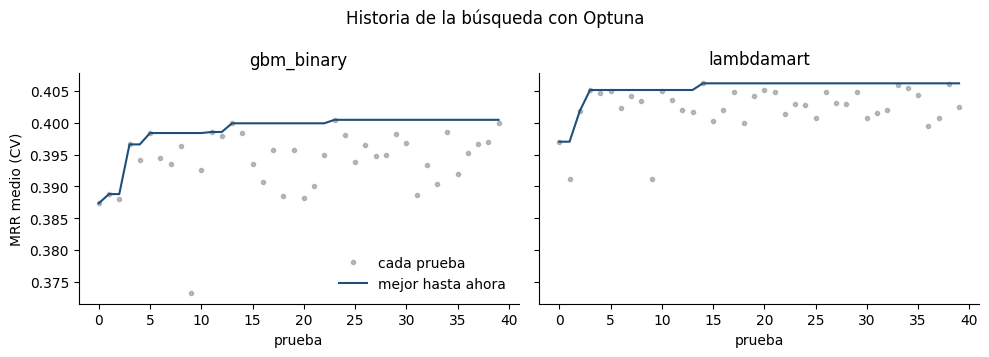

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, m in zip(axes, ["gbm_binary", "lambdamart"]):
    t = pd.read_csv(RES / "tuning" / f"{m}_trials.csv")
    ax.plot(t["number"], t["value"], "o", ms=3, alpha=.5, color="#7f7f7f", label="cada prueba")
    ax.plot(t["number"], t["value"].cummax(), color="#1f4e79", label="mejor hasta ahora")
    ax.set_title(m); ax.set_xlabel("prueba"); ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("MRR medio (CV)"); axes[0].legend(frameon=False)
plt.suptitle("Historia de la búsqueda con Optuna"); plt.tight_layout(); plt.show()

**Cómo leerlo:** si la curva "mejor hasta ahora" se aplana mucho antes de la última prueba, más pruebas no habrían cambiado el resultado: el presupuesto de búsqueda fue suficiente.

## 3. Curvas de aprendizaje: ¿sobreajuste o subajuste?

Se entrena con los últimos *k* años de train (siempre los más recientes, para que la distancia a 2004 sea la misma) y se mide en train y en validación.

- **Brecha grande train − val** → sobreajuste (memoriza).
- **Val sube al agregar años** → más datos ayudarían.
- **Ambas bajas y planas** → subajuste.

**Ojo con val > train:** 2004 fue el año más predecible del período, incluso para el mercado (el favorito acertó 33.1 % en 2004, contra 29.3 % en los años de train y 26.2 % en 2001). Por eso un modelo que no sobreajusta puede salir mejor en validación que en train. Además, el *k* del *shrinkage* del historial se eligió en 2004, lo que deja la validación levemente optimista para todos los modelos por igual; el test (2005) no tiene ese sesgo.

logreg     : MRR train 0.380 vs val 0.420 → brecha -0.039 con todos los años
lambdamart : MRR train 0.460 vs val 0.408 → brecha +0.052 con todos los años


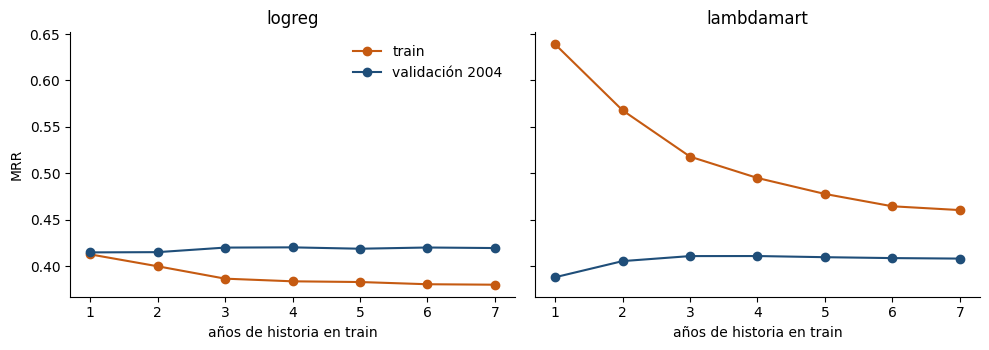

In [9]:
lc_models = [m for m in CFG["learning_curve_models"] if (RES / f"learning_curve_{m}.csv").exists()]
fig, axes = plt.subplots(1, len(lc_models), figsize=(5 * len(lc_models), 3.6), sharey=True)
axes = [axes] if len(lc_models) == 1 else axes
for ax, m in zip(axes, lc_models):
    lc = pd.read_csv(RES / f"learning_curve_{m}.csv").pivot(index="years", columns="part", values="mrr")
    ax.plot(lc.index, lc["train"], "o-", color="#c55a11", label="train")
    ax.plot(lc.index, lc["val"], "o-", color="#1f4e79", label="validación 2004")
    ax.set_title(m); ax.set_xlabel("años de historia en train"); ax.spines[["top", "right"]].set_visible(False)
    gap = lc["train"].iloc[-1] - lc["val"].iloc[-1]
    print(f"{m:11s}: MRR train {lc['train'].iloc[-1]:.3f} vs val {lc['val'].iloc[-1]:.3f} "
          f"→ brecha {gap:+.3f} con todos los años")
axes[0].set_ylabel("MRR"); axes[0].legend(frameon=False)
plt.tight_layout(); plt.show()

## 4. Calibración (modelo propuesto)

LambdaMART devuelve puntajes sin escala. Se convierten en probabilidades con un softmax por carrera y una **temperatura** ajustada solo en validación. Un solo parámetro no cambia el orden (top-1, MRR y NDCG quedan iguales); solo afecta log loss, Brier y ECE.

Si los puntos caen sobre la diagonal, cuando el modelo dice "20 %" el caballo gana ~20 % de las veces.

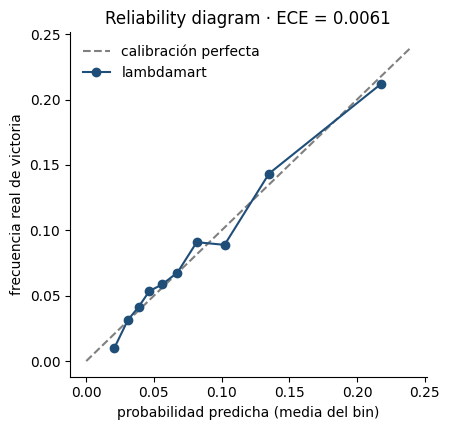

Temperatura ajustada en validación: T = 0.810


In [10]:
rel = pd.read_csv(RES / "val_reliability_lambdamart.csv")
fig, ax = plt.subplots(figsize=(4.6, 4.4))
lim = max(rel["p_mean"].max(), rel["freq"].max()) * 1.1
ax.plot([0, lim], [0, lim], ls="--", color="grey", label="calibración perfecta")
ax.plot(rel["p_mean"], rel["freq"], "o-", color="#1f4e79", label="lambdamart")
ax.set_xlabel("probabilidad predicha (media del bin)"); ax.set_ylabel("frecuencia real de victoria")
ax.set_title(f"Reliability diagram · ECE = {val.loc['lambdamart','ece']:.4f}")
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()
print(f"Temperatura ajustada en validación: T = {val.loc['lambdamart','T']:.3f}")

## 5. Análisis de errores (modelo propuesto)

¿Dónde falla? Top-1 segmentado por tamaño del campo, por la cuota del ganador real y según si el modelo coincidió con el favorito del mercado.

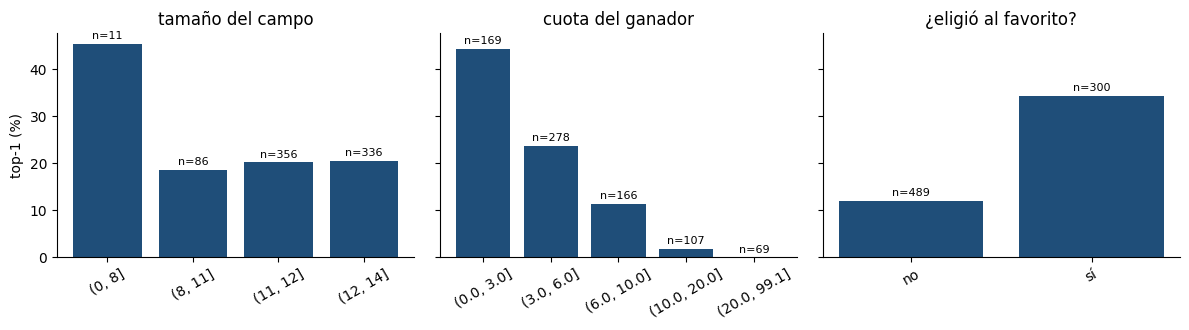

In [11]:
seg = {
    "tamaño del campo": "val_errors_lambdamart_by_field_size.csv",
    "cuota del ganador": "val_errors_lambdamart_by_winner_odds.csv",
    "¿eligió al favorito?": "val_errors_lambdamart_agrees_with_market.csv",
}
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for ax, (titulo, f) in zip(axes, seg.items()):
    d = pd.read_csv(RES / f)
    etiquetas = d.iloc[:, 0].astype(str).replace({"True": "sí", "False": "no"})
    ax.bar(etiquetas, 100 * d["mean"], color="#1f4e79")
    for i, (h, n) in enumerate(zip(100 * d["mean"], d["size"])):
        ax.text(i, h + 1, f"n={n}", ha="center", fontsize=8)
    ax.set_title(titulo); ax.tick_params(axis="x", rotation=30); ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("top-1 (%)")
plt.tight_layout(); plt.show()

**Casos límite:** las carreras donde el modelo estaba más seguro de su elegido y se equivocó (falsos positivos caros), y los ganadores que el modelo dejó más abajo (falsos negativos). Son los casos a discutir en el reporte.

In [12]:
cols = ["race_id", "date", "field_size", "pick_prob", "pick_mkt_rank", "winner_pred_rank", "winner_odds"]
print("Fallos más confiados:")
display(pd.read_csv(RES / "val_confident_misses_lambdamart.csv")[cols].head(10))
print("Ganadores peor ubicados por el modelo:")
display(pd.read_csv(RES / "val_missed_winners_lambdamart.csv")[cols].head(10))

Fallos más confiados:


,race_id,date,field_size,pick_prob,pick_mkt_rank,winner_pred_rank,winner_odds
0,5563,2004-08-29,14,0.4694,1.0000,7.0000,4.1000
1,5786,2004-11-28,6,0.4332,1.0000,2.0000,9.5000
2,5541,2004-08-22,11,0.4242,1.0000,5.0000,7.5000
3,5284,2004-03-17,6,0.4236,1.0000,2.0000,5.6000
4,5507,2004-08-07,9,0.4101,1.0000,6.0000,37.0000
5,5846,2004-12-19,8,0.4039,1.0000,7.0000,6.6000
6,5678,2004-10-17,11,0.3996,1.0000,4.0000,3.8000
7,5596,2004-09-12,14,0.3988,2.0000,5.0000,10.0000
8,5387,2004-06-17,14,0.3822,3.0000,7.0000,3.2000
9,5316,2004-03-28,14,0.3818,1.0000,3.0000,12.0000


Ganadores peor ubicados por el modelo:


,race_id,date,field_size,pick_prob,pick_mkt_rank,winner_pred_rank,winner_odds
0,5298,2004-03-21,14,0.1522,2.0000,14.0000,9.5000
1,5856,2004-12-22,14,0.2369,1.0000,14.0000,11.0000
2,5273,2004-03-13,14,0.1552,7.0000,14.0000,43.0000
3,5526,2004-08-15,14,0.1970,2.0000,13.0000,79.0000
4,5766,2004-11-21,14,0.1614,2.0000,13.0000,6.7000
5,5286,2004-03-17,14,0.1562,7.0000,13.0000,6.6000
6,5715,2004-10-31,14,0.1513,8.0000,13.0000,14.0000
7,5402,2004-06-23,12,0.1621,2.0000,12.0000,11.0000
8,5324,2004-05-23,13,0.1445,6.0000,12.0000,12.0000
9,5781,2004-11-24,12,0.2054,3.0000,12.0000,17.0000


## 6. ¿Cuánto aporta el historial? (v0 sin historial vs. v1 con historial)

Solo se muestra si existe `results_v0/` (ver los comandos al inicio).

In [13]:
if (RES_V0 / "val_metrics.csv").exists():
    v0 = pd.read_csv(RES_V0 / "val_metrics.csv").set_index("model")
    comp = pd.DataFrame({
        "top-1 v0 %": 100 * v0["top1"], "top-1 v1 %": 100 * val["top1"],
        "MRR v0": v0["mrr"], "MRR v1": val["mrr"], "Δ MRR": val["mrr"] - v0["mrr"],
        "log loss v0": v0["log_loss"], "log loss v1": val["log_loss"],
    }).reindex(orden).drop(index=["random", "market"], errors="ignore")
    display(comp)
else:
    print("No hay results_v0/: correr el experimento con dataset_v0 y --out results_v0 para esta comparación.")

,top-1 v0 %,top-1 v1 %,MRR v0,MRR v1,Δ MRR,log loss v0,log loss v1
model,,,,,,,
logreg,18.3777,23.4474,0.3850,0.4196,0.0346,2.3737,2.3310
gbm_binary,18.6312,19.7719,0.3870,0.4104,0.0234,2.3627,2.3121
clogit,18.3777,22.8137,0.3800,0.4144,0.0344,2.3815,2.3421
lambdamart,21.4195,20.5323,0.3981,0.4083,0.0101,2.3593,2.2986


## 7. Test (2005)

Se evalúa **una sola vez**, al final, con `--stage final`. Mientras no exista `results/test_metrics.csv`, esta sección queda vacía a propósito.

In [14]:
if (RES / "test_metrics.csv").exists():
    t = pd.read_csv(RES / "test_metrics.csv").set_index("model").reindex(orden)
    display(t[["n_races", "top1", "top1_lo", "top1_hi", "top1_diff_vs_ref", "mrr", "ndcg@3", "log_loss", "brier_race"]])
else:
    print("Test aún no evaluado (correcto mientras se ajusta y se hace SHAP).")

Test aún no evaluado (correcto mientras se ajusta y se hace SHAP).
